Running on: cuda
GPU: Tesla T4

Upload TSAC Excel or CSV dataset:


Saving TSAC - Telugu Sentiment Analysis Corpus.xlsx to TSAC - Telugu Sentiment Analysis Corpus (2).xlsx

Dataset shape: (1287, 3)
Available columns: ['statement', 'label', 'translated_english']


,statement,label,translated_english
0,ప్రేక్షకులను మోసం చేయడం తప్ప ఏం లేదు మూవీ లో ...,Negative,What if you want to make a movie in a new worl...
1,నువ్వు దైర్యంగా అది రాడ్డు మూవీ అని ఒప్పుకున్న...,Positive,You should admire that you are bravely admitte...
2,దేవర కంకర రాడ్డు మూవీ అయినా ఫాన్స్ కి భయపడి చా...,Negative,"Devara's gravel rod movie, but many people hav..."
3,ఏరా 'బూరు బుల్లా'.. ఏంట్రా నీ చెత్త లో రివ్యూ....,Negative,Are you a 'boor bulla'.. or is your review rub...
4,దేవర మూవీ నాకు కొంచెం కూడా నచ్చలేదు. కానీ మీరు...,Negative,I didn't like the movie Devara at all. But whe...



Sentiment distribution:
label
Negative    420
Neutral     418
Positive    438
Name: count, dtype: int64

Final dataset size: 1276
Sentiment classes: ['Negative', 'Neutral', 'Positive']

Training reviews: 892
Validation reviews: 192
Testing reviews: 192

Loading MuRIL tokenizer: google/muril-base-cased

Loading pretrained MuRIL model...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w


MODEL SUMMARY
Model name       : google/muril-base-cased
Architecture     : BERT
Hidden size      : 768
Transformer layers: 12
Attention heads  : 12
Maximum sequence : 128
Output classes   : 3
Class names      : ['Negative', 'Neutral', 'Positive']
Total parameters     : 237,558,531
Trainable parameters : 237,558,531
Model size (FP32)    : 906.21 MB

Class weights:
Negative: 1.011
Neutral: 1.018
Positive: 0.972

Starting training...

Epoch 1/5
Batch 20/112 | Loss: 1.0978
Batch 40/112 | Loss: 1.0987
Batch 60/112 | Loss: 1.0993
Batch 80/112 | Loss: 1.0962
Batch 100/112 | Loss: 1.0899
Batch 112/112 | Loss: 1.0905
Training Loss   : 1.0967
Validation Loss : 1.0834
Validation Acc  : 57.81%
Validation Macro F1: 0.5159
Best validation model saved in memory.

Epoch 2/5
Batch 20/112 | Loss: 1.0739
Batch 40/112 | Loss: 1.0597
Batch 60/112 | Loss: 1.0764
Batch 80/112 | Loss: 1.0022
Batch 100/112 | Loss: 1.0267
Batch 112/112 | Loss: 0.9578
Training Loss   : 1.0498
Validation Loss : 1.0199
Validatio

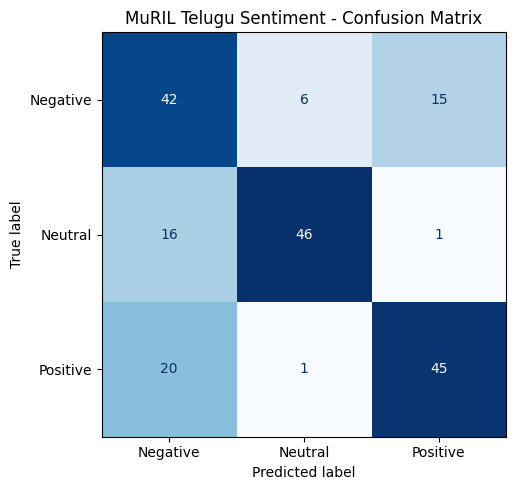

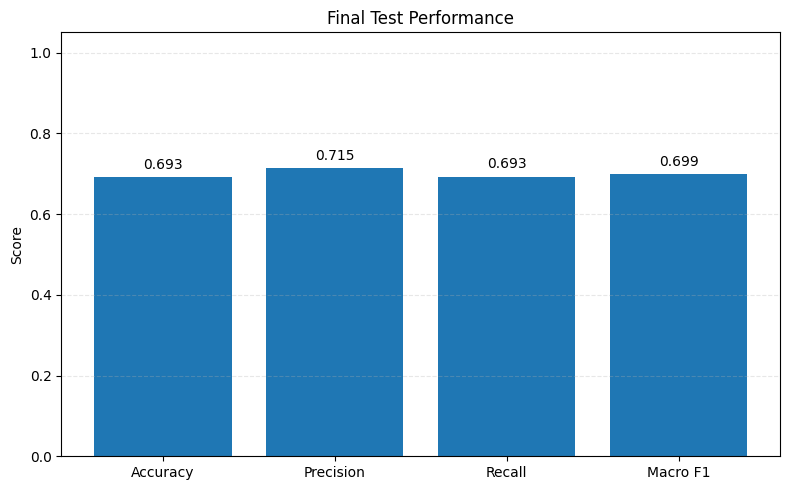

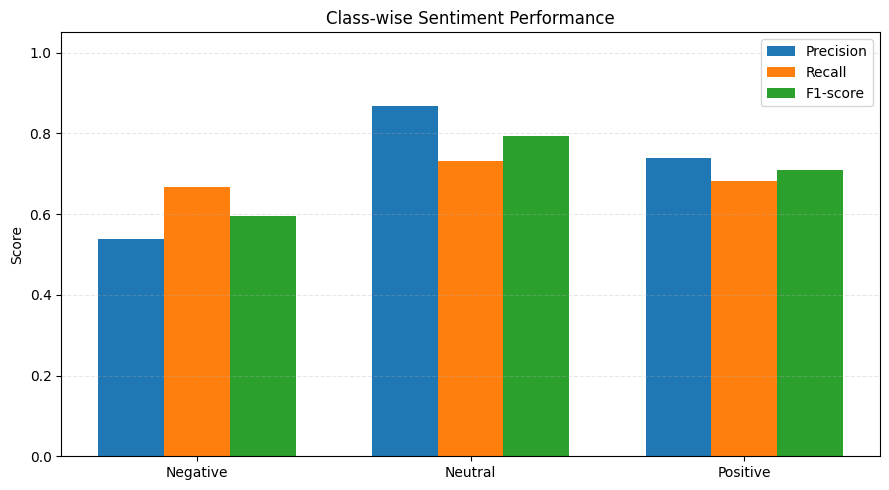

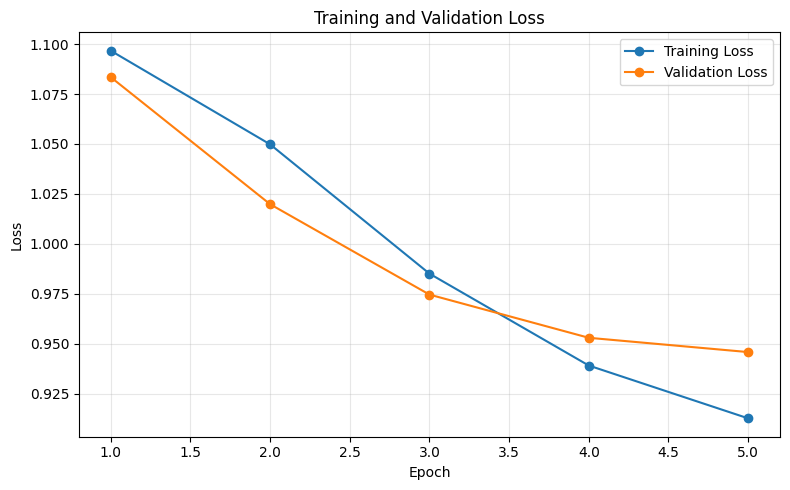

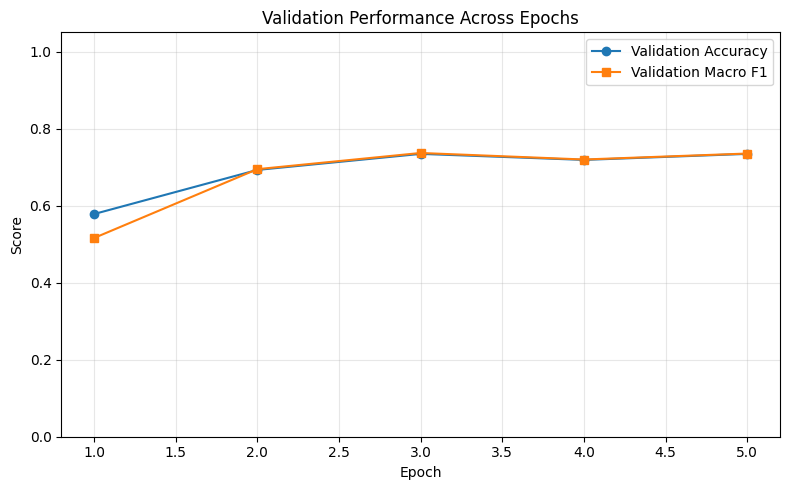


TELUGU SENTIMENT PREDICTIONS

Review 1
Movie Name          : Not identified
Review              : ప్రేమ అని అనుకునేటోడు ఈ మూవీ చూడండి ర బాబు ప్రేమ మొదటిలో ఉనంత ప్రేమ ముగింపులో ఉండదు.....
Actual Sentiment    : Negative
Predicted Sentiment : Positive
Confidence          : 39.14%
Result              : Incorrect

Review 2
Movie Name          : Not identified
Review              : నేషనల్ పార్క్‌గా గుర్తింపు ఇవ్వండి, జింకలను, నెమలిలను కాపాడండి
Actual Sentiment    : Positive
Predicted Sentiment : Negative
Confidence          : 34.61%
Result              : Incorrect

Review 3
Movie Name          : Not identified
Review              : దీని మీద ఉన్న ఇంట్రెస్ట్ మొత్తం పోయింది. ఈ వీడియో దెబ్బకి.
Actual Sentiment    : Negative
Predicted Sentiment : Negative
Confidence          : 38.58%
Result              : Correct

Review 4
Movie Name          : Not identified
Review              : మాకు మొబైల్స్ కొనడానకే కష్టంగా ఉంది; car అంటే అది… ఇదైయితే మీ వీడియో చూడమే…😔😔👍
Actual Sentiment    : Negative
Predic

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Predictions saved to: telugu_sentiment_predictions.csv
Fine-tuned model saved to: telugu_muril_sentiment_model


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Experiment completed successfully.


In [ ]:
# ============================================================
# TELUGU SENTIMENT ANALYSIS USING MuRIL
# Dataset: TSAC - Telugu Sentiment Analysis Corpus
# Classes: Negative, Neutral, Positive
# ============================================================

import re
import copy
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from google.colab import files
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

# -------------------- 1. SETTINGS --------------------

SEED = 42
MODEL_NAME = "google/muril-base-cased"

MAX_LENGTH = 128
BATCH_SIZE = 8
EPOCHS = 5
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 0.01
PATIENCE = 2

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# -------------------- 2. UPLOAD DATASET --------------------

print("\nUpload TSAC Excel or CSV dataset:")
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(filename)
elif filename.lower().endswith(".csv"):
    df = pd.read_csv(filename, encoding="utf-8")
else:
    raise ValueError("Upload an Excel or CSV file.")

df.columns = [
    re.sub(r"\s+", "_", str(c).strip().lower())
    for c in df.columns
]

print("\nDataset shape:", df.shape)
print("Available columns:", df.columns.tolist())
display(df.head())

REVIEW_COL = "statement"
SENTIMENT_COL = "label"

if REVIEW_COL not in df.columns or SENTIMENT_COL not in df.columns:
    raise ValueError(
        "Required columns 'statement' and 'label' were not found."
    )

# -------------------- 3. DATA PREPROCESSING --------------------

df = df.dropna(subset=[REVIEW_COL, SENTIMENT_COL]).copy()
df[REVIEW_COL] = df[REVIEW_COL].astype(str).str.strip()
df["label"] = df[SENTIMENT_COL].astype(str).str.strip().str.title()

df = df[
    (df[REVIEW_COL] != "") &
    (df["label"].isin(["Negative", "Neutral", "Positive"]))
].copy()

# Avoid keeping repeated copies of the same text.
df = df.drop_duplicates(subset=[REVIEW_COL]).reset_index(drop=True)

class_names = ["Negative", "Neutral", "Positive"]
label2id = {name: i for i, name in enumerate(class_names)}
id2label = {i: name for name, i in label2id.items()}

df["label_id"] = df["label"].map(label2id).astype(int)

print("\nSentiment distribution:")
print(df["label"].value_counts().reindex(class_names, fill_value=0))

print("\nFinal dataset size:", len(df))
print("Sentiment classes:", class_names)

if df["label"].nunique() != 3:
    raise ValueError("The dataset must contain all three sentiment classes.")

# -------------------- 4. STRATIFIED DATA SPLIT --------------------

train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    random_state=SEED,
    stratify=df["label_id"]
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.1765,
    random_state=SEED,
    stratify=train_val_df["label_id"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nTraining reviews:", len(train_df))
print("Validation reviews:", len(val_df))
print("Testing reviews:", len(test_df))

# -------------------- 5. TOKENIZER --------------------

print("\nLoading MuRIL tokenizer:", MODEL_NAME)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class TeluguDataset(Dataset):
    def __init__(self, data):
        self.texts = data[REVIEW_COL].tolist()
        self.labels = data["label_id"].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoded = tokenizer(
            self.texts[index],
            max_length=MAX_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        return {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                self.labels[index], dtype=torch.long
            )
        }

train_loader = DataLoader(
    TeluguDataset(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    TeluguDataset(val_df),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    TeluguDataset(test_df),
    batch_size=BATCH_SIZE,
    shuffle=False
)

# -------------------- 6. LOAD MuRIL MODEL --------------------

print("\nLoading pretrained MuRIL model...")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(class_names),
    id2label=id2label,
    label2id=label2id
).to(device)

print("\n" + "=" * 60)
print("MODEL SUMMARY")
print("=" * 60)
print("Model name       :", MODEL_NAME)
print("Architecture     :", model.config.model_type.upper())
print("Hidden size      :", model.config.hidden_size)
print("Transformer layers:", model.config.num_hidden_layers)
print("Attention heads  :", model.config.num_attention_heads)
print("Maximum sequence :", MAX_LENGTH)
print("Output classes   :", len(class_names))
print("Class names      :", class_names)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Model size (FP32)    : {total_params * 4 / (1024**2):.2f} MB")
print("=" * 60)

# -------------------- 7. CLASS-WEIGHTED LOSS --------------------

# Gives relatively more weight to classes with fewer examples.
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=train_df["label_id"].to_numpy()
)

class_weights = torch.tensor(
    weights, dtype=torch.float32
).to(device)

print("\nClass weights:")
for name, weight in zip(class_names, weights):
    print(f"{name}: {weight:.3f}")

criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

# -------------------- 8. OPTIMIZER AND SCHEDULER --------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = len(train_loader) * EPOCHS
warmup_steps = int(0.10 * total_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

# -------------------- 9. EVALUATION FUNCTION --------------------

def evaluate(loader):
    model.eval()

    total_loss = 0.0
    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = criterion(outputs.logits, labels)
            predictions = torch.argmax(outputs.logits, dim=1)

            total_loss += loss.item()
            true_labels.extend(labels.cpu().numpy())
            predicted_labels.extend(predictions.cpu().numpy())

    avg_loss = total_loss / max(len(loader), 1)
    accuracy = accuracy_score(true_labels, predicted_labels)
    macro_f1 = f1_score(
        true_labels,
        predicted_labels,
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1

# -------------------- 10. TRAIN WITH EARLY STOPPING --------------------

train_losses = []
val_losses = []
val_accuracies = []
val_f1_scores = []

best_val_f1 = -1.0
best_epoch = 0
best_state = None
epochs_without_improvement = 0

print("\nStarting training...")

for epoch in range(EPOCHS):
    model.train()
    total_train_loss = 0.0

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    for step, batch in enumerate(train_loader, start=1):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion(outputs.logits, labels)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_train_loss += loss.item()

        if step % 20 == 0 or step == len(train_loader):
            print(
                f"Batch {step}/{len(train_loader)} "
                f"| Loss: {loss.item():.4f}"
            )

    avg_train_loss = total_train_loss / max(len(train_loader), 1)

    val_loss, val_acc, val_f1 = evaluate(val_loader)

    train_losses.append(avg_train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)
    val_f1_scores.append(val_f1)

    print(f"Training Loss   : {avg_train_loss:.4f}")
    print(f"Validation Loss : {val_loss:.4f}")
    print(f"Validation Acc  : {val_acc * 100:.2f}%")
    print(f"Validation Macro F1: {val_f1:.4f}")

    # Select the model using validation macro F1.
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch + 1
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        epochs_without_improvement = 0
        print("Best validation model saved in memory.")
    else:
        epochs_without_improvement += 1
        print(
            f"No improvement: "
            f"{epochs_without_improvement}/{PATIENCE}"
        )

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping activated.")
        break

# Restore the best validation model.
if best_state is not None:
    model.load_state_dict(best_state)

model.to(device)

print("\nBest epoch:", best_epoch)
print(f"Best validation Macro F1: {best_val_f1:.4f}")

# -------------------- 11. FINAL TEST EVALUATION --------------------

model.eval()
y_true = []
y_pred = []
y_confidence = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.softmax(outputs.logits, dim=1)
        predictions = probabilities.argmax(dim=1)
        confidence = probabilities.max(dim=1).values

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_confidence.extend(
            (confidence.cpu().numpy() * 100).tolist()
        )

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n" + "=" * 65)
print("FINAL TEST PERFORMANCE")
print("=" * 65)
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"Macro F1  : {f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# -------------------- 12. CONFUSION MATRIX --------------------

cm = confusion_matrix(
    y_true, y_pred, labels=list(range(len(class_names)))
)

print("\nCONFUSION MATRIX")
print(pd.DataFrame(
    cm,
    index=[f"Actual {c}" for c in class_names],
    columns=[f"Predicted {c}" for c in class_names]
))

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("MuRIL Telugu Sentiment - Confusion Matrix")
plt.tight_layout()
plt.show()

# -------------------- 13. OVERALL METRICS GRAPH --------------------

metric_names = ["Accuracy", "Precision", "Recall", "Macro F1"]
metric_values = [accuracy, precision, recall, f1]

plt.figure(figsize=(8, 5))
bars = plt.bar(metric_names, metric_values)

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Final Test Performance")

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------- 14. CLASS-WISE METRICS GRAPH --------------------

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

x = np.arange(len(class_names))
width = 0.24

plt.figure(figsize=(9, 5))
plt.bar(
    x - width,
    [report[c]["precision"] for c in class_names],
    width,
    label="Precision"
)
plt.bar(
    x,
    [report[c]["recall"] for c in class_names],
    width,
    label="Recall"
)
plt.bar(
    x + width,
    [report[c]["f1-score"] for c in class_names],
    width,
    label="F1-score"
)

plt.xticks(x, class_names)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Class-wise Sentiment Performance")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------- 15. TRAINING CURVES --------------------

epochs_run = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_run, train_losses, marker="o", label="Training Loss")
plt.plot(epochs_run, val_losses, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    epochs_run,
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)
plt.plot(
    epochs_run,
    val_f1_scores,
    marker="s",
    label="Validation Macro F1"
)
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Performance Across Epochs")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------- 16. TEST REVIEW PREDICTIONS --------------------

results = test_df.copy().reset_index(drop=True)

results["Actual Sentiment"] = results["label"]
results["Predicted Sentiment"] = [
    id2label[int(p)] for p in y_pred
]
results["Confidence (%)"] = np.round(y_confidence, 2)
results["Result"] = np.where(
    results["Actual Sentiment"] == results["Predicted Sentiment"],
    "Correct",
    "Incorrect"
)

def extract_movie_name(review):
    # Only return a movie name if the review explicitly mentions
    # one of the known titles. Otherwise, do not invent a title.
    known_movies = [
        "Pushpa 2", "Pushpa", "Baahubali 2", "Baahubali",
        "Devara", "RRR", "Salaar", "Kalki 2898 AD",
        "Animal", "Arjun Reddy", "Jersey", "Mahanati",
        "Rangasthalam", "Magadheera", "Eega", "Pokiri",
        "Athadu", "Guntur Kaaram", "Hanu-Man", "Sita Ramam",
        "Hi Nanna", "Dasara", "Game Changer", "Tillu Square"
    ]

    text = str(review).lower()
    for title in sorted(known_movies, key=len, reverse=True):
        if title.lower() in text:
            return title
    return "Not identified"

results["Movie Name"] = results[REVIEW_COL].apply(extract_movie_name)

print("\n" + "=" * 75)
print("TELUGU SENTIMENT PREDICTIONS")
print("=" * 75)

for i, row in results.head(20).iterrows():
    print(f"\nReview {i + 1}")
    print("Movie Name          :", row["Movie Name"])
    print("Review              :", str(row[REVIEW_COL])[:400])
    print("Actual Sentiment    :", row["Actual Sentiment"])
    print("Predicted Sentiment :", row["Predicted Sentiment"])
    print(f"Confidence          : {row['Confidence (%)']:.2f}%")
    print("Result              :", row["Result"])

# -------------------- 17. PREDICT A NEW TELUGU REVIEW --------------------

def predict_sentiment(review):
    model.eval()

    encoded = tokenizer(
        review,
        return_tensors="pt",
        max_length=MAX_LENGTH,
        truncation=True,
        padding=True
    )

    encoded = {k: v.to(device) for k, v in encoded.items()}

    with torch.no_grad():
        logits = model(**encoded).logits
        probs = torch.softmax(logits, dim=1)[0]

    pred_id = int(probs.argmax().item())
    confidence = float(probs[pred_id].item()) * 100

    return id2label[pred_id], confidence

print("\nTry a new Telugu review:")
new_review = input("Enter review: ").strip()

if new_review:
    sentiment, confidence = predict_sentiment(new_review)
    print("Predicted Sentiment:", sentiment)
    print(f"Confidence: {confidence:.2f}%")

# -------------------- 18. SAVE MODEL AND RESULTS --------------------

output_csv = "telugu_sentiment_predictions.csv"
results[
    [
        "Movie Name", REVIEW_COL,
        "Actual Sentiment", "Predicted Sentiment",
        "Confidence (%)", "Result"
    ]
].to_csv(output_csv, index=False, encoding="utf-8-sig")

model_dir = "telugu_muril_sentiment_model"
model.save_pretrained(model_dir)
tokenizer.save_pretrained(model_dir)

print("\nPredictions saved to:", output_csv)
print("Fine-tuned model saved to:", model_dir)
files.download(output_csv)

print("\nExperiment completed successfully.")